In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carga del conjunto de datos
df = pd.read_csv("../conjunto_de_datos_morbilid_esep_2025.csv")

# Verificación de volumen de datos
print(f"Número de filas: {df.shape[0]}")
print(f"Número de columnas: {df.shape[1]}")
df.head()

Número de filas: 152892
Número de columnas: 10


,smoanio,smoentidad,smomunic,smoconsec,smoclave,smototal,smohomb,smomuje,smodias,smodefun
0,2025,1,1,1,59,10,2,8,11,0
1,2025,1,1,1,64,7,1,6,7,0
2,2025,1,1,1,83,2,0,2,2,0
3,2025,1,1,1,112,1,1,0,2,0
4,2025,1,1,1,117,333,24,309,379,0


In [21]:
# Exploración inicial de los datos
df.info()
print("\nValores nulos por columna:")
print(df.isnull().sum())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")
df[["smototal", "smohomb", "smomuje", "smodias", "smodefun"]].describe().T

<class 'pandas.DataFrame'>
RangeIndex: 152892 entries, 0 to 152891
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   smoanio     152892 non-null  int64
 1   smoentidad  152892 non-null  int64
 2   smomunic    152892 non-null  int64
 3   smoconsec   152892 non-null  int64
 4   smoclave    152892 non-null  int64
 5   smototal    152892 non-null  int64
 6   smohomb     152892 non-null  int64
 7   smomuje     152892 non-null  int64
 8   smodias     152892 non-null  int64
 9   smodefun    152892 non-null  int64
dtypes: int64(10)
memory usage: 11.7 MB

Valores nulos por columna:
smoanio       0
smoentidad    0
smomunic      0
smoconsec     0
smoclave      0
smototal      0
smohomb       0
smomuje       0
smodias       0
smodefun      0
dtype: int64

Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
smototal,152892.0,47.773173,401.447189,0.0,2.0,5.0,20.0,66387.0
smohomb,152892.0,19.042847,193.907461,0.0,0.0,2.0,7.0,37671.0
smomuje,152892.0,28.730326,218.030613,0.0,1.0,3.0,11.0,28716.0
smodias,152892.0,95.011891,743.990509,0.0,3.0,10.0,37.0,66387.0
smodefun,152892.0,0.370163,3.125179,0.0,0.0,0.0,0.0,243.0


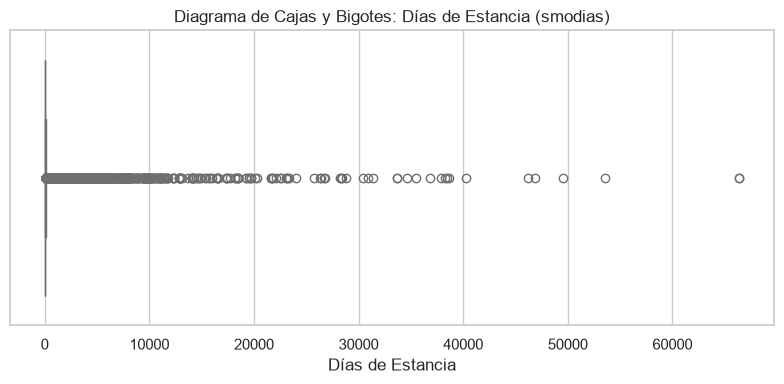

In [22]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["smodias"], color="skyblue")
plt.title("Diagrama de Cajas y Bigotes: Días de Estancia (smodias)")
plt.xlabel("Días de Estancia")
plt.tight_layout()
plt.show()

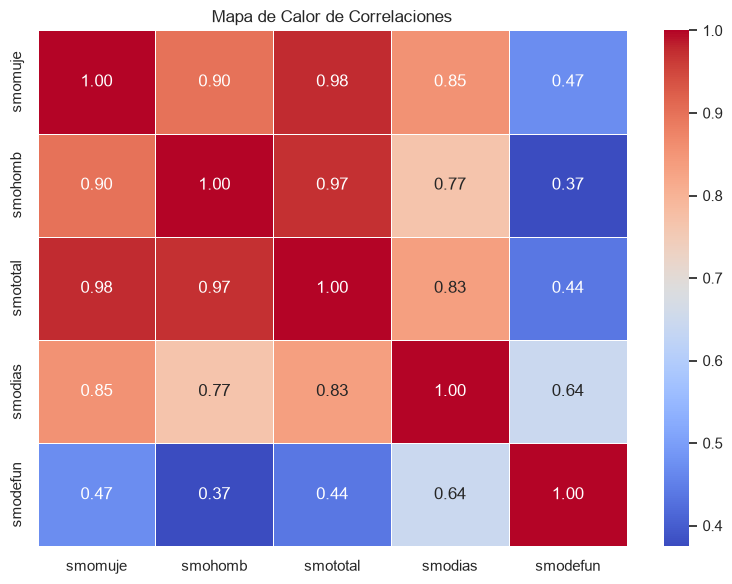

In [23]:
plt.figure(figsize=(8, 6))
columnas_num = ["smomuje", "smohomb", "smototal", "smodias", "smodefun"]
matriz_corr = df[columnas_num].corr()

sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Mapa de Calor de Correlaciones")
plt.tight_layout()
plt.show()

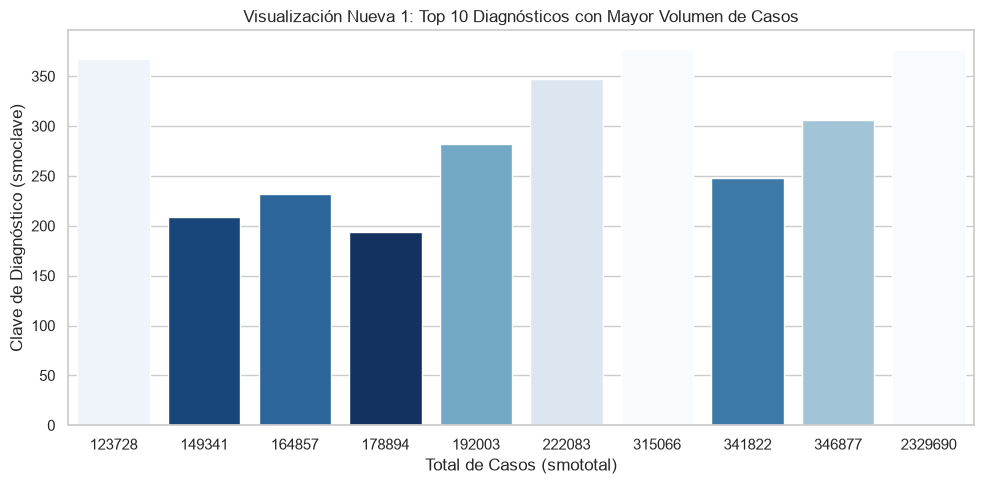

In [24]:
plt.figure(figsize=(10, 5))
top_claves = (
    df.groupby("smoclave")["smototal"].sum().nlargest(10).reset_index()
)
sns.barplot(
    data=top_claves, x="smototal", y="smoclave", palette="Blues_r", hue="smoclave", legend=False
)
plt.title("Visualización Nueva 1: Top 10 Diagnósticos con Mayor Volumen de Casos")
plt.xlabel("Total de Casos (smototal)")
plt.ylabel("Clave de Diagnóstico (smoclave)")
plt.tight_layout()
plt.show()

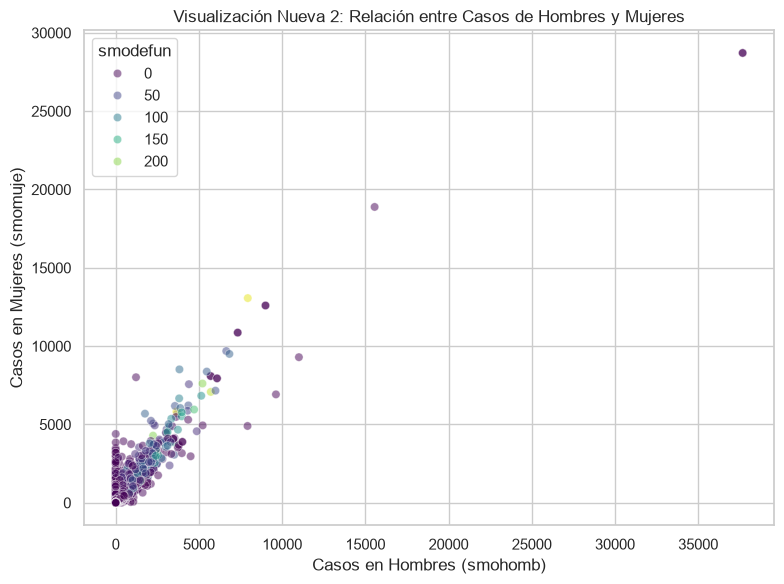

In [25]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="smohomb",
    y="smomuje",
    alpha=0.5,
    hue="smodefun",
    palette="viridis",
)
plt.title("Visualización Nueva 2: Relación entre Casos de Hombres y Mujeres")
plt.xlabel("Casos en Hombres (smohomb)")
plt.ylabel("Casos en Mujeres (smomuje)")
plt.tight_layout()
plt.show()

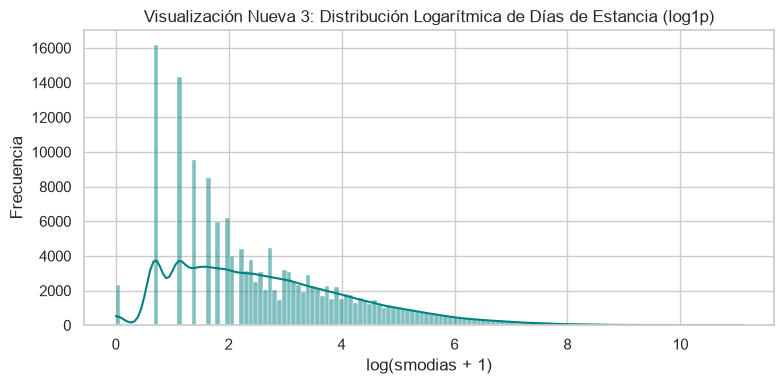

In [26]:
plt.figure(figsize=(8, 4))
sns.histplot(np.log1p(df["smodias"]), kde=True, color="teal")
plt.title("Visualización Nueva 3: Distribución Logarítmica de Días de Estancia (log1p)")
plt.xlabel("log(smodias + 1)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()